In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries loaded successfully!")

Libraries loaded successfully!


In [2]:
df = pd.read_json("../data/raw/Electronics_5.json", lines=True)

print("Dataset loaded successfully!")
print("Shape:", df.shape)

Dataset loaded successfully!
Shape: (1689188, 9)


In [3]:
df.head()

,reviewerID,asin,reviewerName,helpful,reviewText,overall,summary,unixReviewTime,reviewTime
0,AO94DHGC771SJ,0528881469,amazdnu,"[0, 0]",We got this GPS for my husband who is an (OTR)...,5,Gotta have GPS!,1370131200,"06 2, 2013"
1,AMO214LNFCEI4,0528881469,Amazon Customer,"[12, 15]","I'm a professional OTR truck driver, and I bou...",1,Very Disappointed,1290643200,"11 25, 2010"
2,A3N7T0DY83Y4IG,0528881469,C. A. Freeman,"[43, 45]","Well, what can I say. I've had this unit in m...",3,1st impression,1283990400,"09 9, 2010"
3,A1H8PY3QHMQQA0,0528881469,"Dave M. Shaw ""mack dave""","[9, 10]","Not going to write a long review, even thought...",2,"Great grafics, POOR GPS",1290556800,"11 24, 2010"
4,A24EV6RXELQZ63,0528881469,Wayne Smith,"[0, 0]",I've had mine for a year and here's what we go...,1,"Major issues, only excuses for support",1317254400,"09 29, 2011"


In [4]:
print(df.columns.tolist())

['reviewerID', 'asin', 'reviewerName', 'helpful', 'reviewText', 'overall', 'summary', 'unixReviewTime', 'reviewTime']


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1689188 entries, 0 to 1689187
Data columns (total 9 columns):
 #   Column          Non-Null Count    Dtype 
---  ------          --------------    ----- 
 0   reviewerID      1689188 non-null  str   
 1   asin            1689188 non-null  str   
 2   reviewerName    1664458 non-null  str   
 3   helpful         1689188 non-null  object
 4   reviewText      1689188 non-null  str   
 5   overall         1689188 non-null  int64 
 6   summary         1689188 non-null  str   
 7   unixReviewTime  1689188 non-null  int64 
 8   reviewTime      1689188 non-null  str   
dtypes: int64(2), object(1), str(6)
memory usage: 1.2+ GB


In [6]:
df.isnull().sum()

reviewerID            0
asin                  0
reviewerName      24730
helpful               0
reviewText            0
overall               0
summary               0
unixReviewTime        0
reviewTime            0
dtype: int64

In [8]:
print("Duplicate reviews:", df.duplicated(
    subset=["reviewerID", "asin", "reviewText", "overall", "summary"]
).sum())

Duplicate reviews: 0


In [9]:
print(df["overall"].value_counts().sort_index())

overall
1     108725
2      82139
3     142257
4     347041
5    1009026
Name: count, dtype: int64


In [10]:
print("Total reviews:", len(df))

print("\nRating percentages:")
print(
    (df["overall"].value_counts(normalize=True).sort_index() * 100)
    .round(2)
)

Total reviews: 1689188

Rating percentages:
overall
1     6.44
2     4.86
3     8.42
4    20.54
5    59.73
Name: proportion, dtype: float64


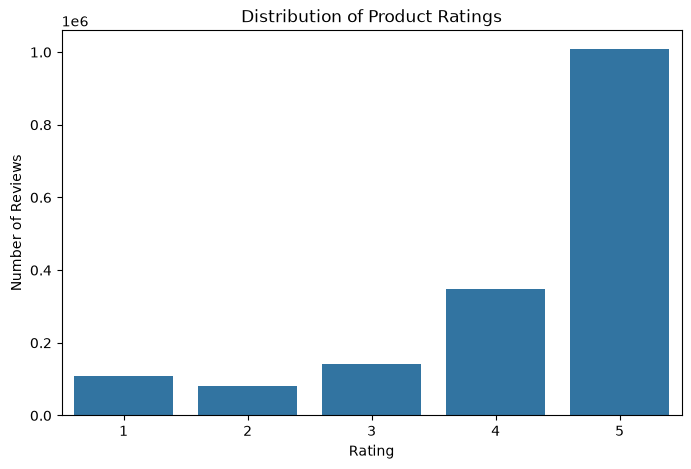

In [11]:
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x="overall")

plt.title("Distribution of Product Ratings")
plt.xlabel("Rating")
plt.ylabel("Number of Reviews")

plt.show()

In [12]:
print(df["reviewText"].head(10).to_string())

0    We got this GPS for my husband who is an (OTR)...
1    I'm a professional OTR truck driver, and I bou...
2    Well, what can I say.  I've had this unit in m...
3    Not going to write a long review, even thought...
4    I've had mine for a year and here's what we go...
5    I am using this with a Nook HD+. It works as d...
6    The cable is very wobbly and sometimes disconn...
7    This adaptor is real easy to setup and use rig...
8    This adapter easily connects my Nook HD 7&#34;...
9    This product really works great but I found th...


In [13]:
print("Missing review texts:", df["reviewText"].isna().sum())

Missing review texts: 0


In [14]:
df["review_length"] = df["reviewText"].fillna("").astype(str).str.len()

print(df["review_length"].describe())

count    1.689188e+06
mean     6.342017e+02
std      9.030145e+02
min      0.000000e+00
25%      1.770000e+02
50%      3.420000e+02
75%      7.240000e+02
max      3.270300e+04
Name: review_length, dtype: float64


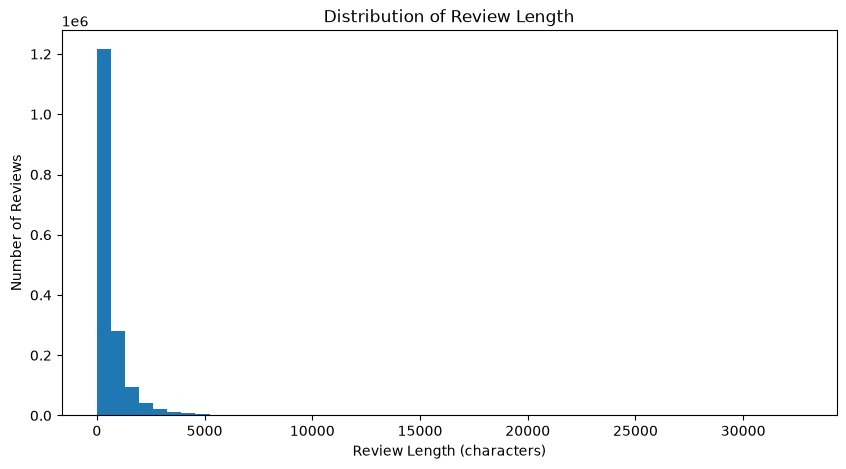

In [15]:
plt.figure(figsize=(10, 5))

plt.hist(df["review_length"], bins=50)

plt.title("Distribution of Review Length")
plt.xlabel("Review Length (characters)")
plt.ylabel("Number of Reviews")

plt.show()

In [16]:
df_clean = df.copy()

print("Original rows:", len(df_clean))

Original rows: 1689188


In [ ]:
#removes rows with null text or values
df_clean = df_clean.dropna(subset=["reviewText"])

print("Rows after removing missing reviews:", len(df_clean))

Rows after removing missing reviews: 1689188


In [ ]:
# remove rows having duplicate data
df_clean = df_clean.drop_duplicates(
    subset=["reviewerID", "asin", "reviewText", "overall", "summary"]
)

print("Rows after removing duplicates:", len(df_clean))

Rows after removing duplicates: 1689188


In [19]:
print("Remaining rows:", len(df_clean))
print("Missing review text:", df_clean["reviewText"].isna().sum())

Remaining rows: 1689188
Missing review text: 0


In [20]:
#creating labels
def rating_to_sentiment(rating):
    if rating <= 2:
        return "negative"
    elif rating == 3:
        return "neutral"
    else:
        return "positive"

df_clean["sentiment"] = df_clean["overall"].apply(rating_to_sentiment)

df_clean[["overall", "sentiment"]].head(10)

,overall,sentiment
0,5,positive
1,1,negative
2,3,neutral
3,2,negative
4,1,negative
5,5,positive
6,2,negative
7,5,positive
8,4,positive
9,5,positive


In [ ]:
#overall sentiment distribution
print(df_clean["sentiment"].value_counts())

sentiment
positive    1356067
negative     190864
neutral      142257
Name: count, dtype: int64


In [22]:
print(
    (df_clean["sentiment"].value_counts(normalize=True) * 100).round(2)
)

sentiment
positive    80.28
negative    11.30
neutral      8.42
Name: proportion, dtype: float64


In [24]:
# Create balanced dataset

SAMPLE_SIZE = 50000

positive_df = df_clean[df_clean["sentiment"] == "positive"].sample(
    n=SAMPLE_SIZE,
    random_state=42
)

negative_df = df_clean[df_clean["sentiment"] == "negative"].sample(
    n=SAMPLE_SIZE,
    random_state=42
)

neutral_df = df_clean[df_clean["sentiment"] == "neutral"].sample(
    n=SAMPLE_SIZE,
    random_state=42
)

df_balanced = pd.concat(
    [positive_df, negative_df, neutral_df],
    ignore_index=True
)

# Shuffle the dataset
df_balanced = df_balanced.sample(
    frac=1,
    random_state=42
).reset_index(drop=True)

print("Balanced dataset shape:", df_balanced.shape)
print("\nSentiment distribution:")
print(df_balanced["sentiment"].value_counts())

Balanced dataset shape: (150000, 11)

Sentiment distribution:
sentiment
negative    50000
positive    50000
neutral     50000
Name: count, dtype: int64


In [25]:
X = df_balanced["reviewText"]
y = df_balanced["sentiment"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (150000,)
y shape: (150000,)


In [26]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training reviews:", len(X_train))
print("Testing reviews:", len(X_test))

Training reviews: 120000
Testing reviews: 30000


In [27]:
df = pd.read_json("../data/raw/Electronics_5.json", lines=True)

In [28]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(
    lowercase=True,
    stop_words="english",
    max_features=50000,
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.95
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("Training TF-IDF shape:", X_train_tfidf.shape)
print("Testing TF-IDF shape:", X_test_tfidf.shape)

Training TF-IDF shape: (120000, 50000)
Testing TF-IDF shape: (30000, 50000)


In [29]:
from sklearn.linear_model import LogisticRegression

In [30]:
model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

In [31]:
model.fit(X_train_tfidf, y_train)

,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lb

In [32]:
y_pred = model.predict(X_test_tfidf)

In [35]:
print(y_pred[:20])

['neutral' 'neutral' 'neutral' 'neutral' 'negative' 'neutral' 'positive'
 'negative' 'negative' 'positive' 'positive' 'neutral' 'negative'
 'neutral' 'negative' 'neutral' 'neutral' 'negative' 'negative' 'negative']
